In [1]:
#Use Forward (explicit) Euler and Backward (implicit) Euler and Predictor-Corrector methods to solve and the following differential equations and compare
# with analytical form over range x ∈ [0, 2] and x ∈ [0, π/5] for the first and the seconddifferential equations respectively by plotting .
#  Use multiple step sizes 0.02, 0.1, 0.3, 0.5 in both the cases.

import math
import library

def forward_euler(f, x0, y0, xend, h):
    steps = int(round((xend - x0) / h))
    x_vals, y_vals = [x0], [y0]
    
    x, y = x0, y0
    for i in range(steps):
        y = y + h * f(x, y)
        x = x + h
        x_vals.append(x)
        y_vals.append(y)
    return x_vals, y_vals


def backward_euler(f, dfdy, x0, y0, xend, h):
    steps = int(round((xend - x0) / h))
    x_vals, y_vals = [x0], [y0]
    x, y = x0, y0
    
    for i in range(steps):
        xn = x + h
        yc = y

        def g(yn):
            return yn - yc - h * f(xn, yn)
            
        def dg(yn):
            return 1.0 - h * dfdy(xn, yn)
        yguess = yc + h * f(x, yc)
        
        nr_result = library.newton_raphson(g, dg, yguess)[0]
        if nr_result is not None:
            y = nr_result
        else:
            y = yguess 
            
        x = xn
        x_vals.append(x)
        y_vals.append(y)
    return x_vals, y_vals


def predictor_corrector(f, x0, y0, xend, h):
    steps = int(round((xend - x0) / h))
    x_vals, y_vals = [x0], [y0]
    
    x, y = x0, y0
    for i in range(steps):
        fc = f(x, y)
        y_predict = y + h * fc
        xn = x + h
        y = y + (h / 2.0) * (fc + f(xn, y_predict))
        x = xn
        x_vals.append(x)
        y_vals.append(y)
    return x_vals, y_vals



method did not converge after 1000 iterations
method did not converge after 1000 iterations
method did not converge after 1000 iterations
method did not converge after 1000 iterations
method did not converge after 1000 iterations


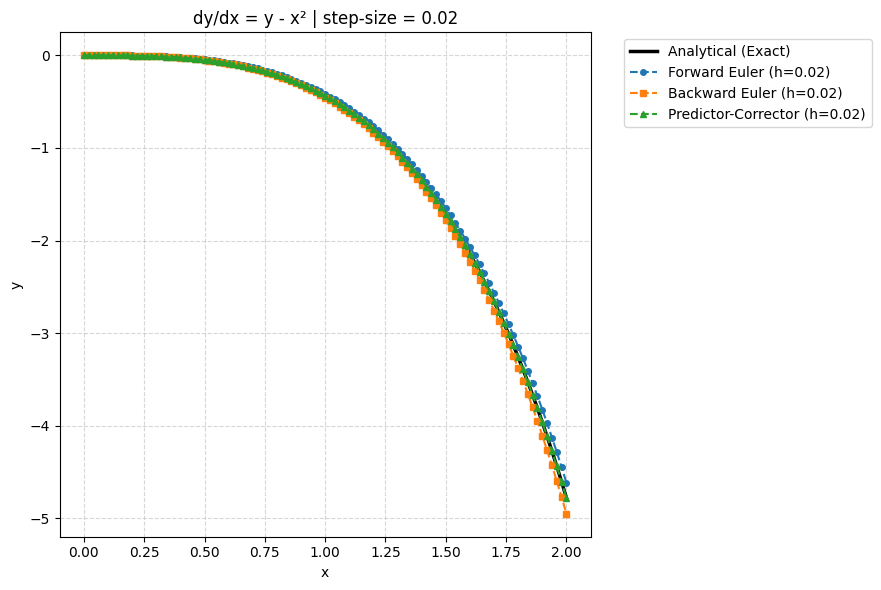

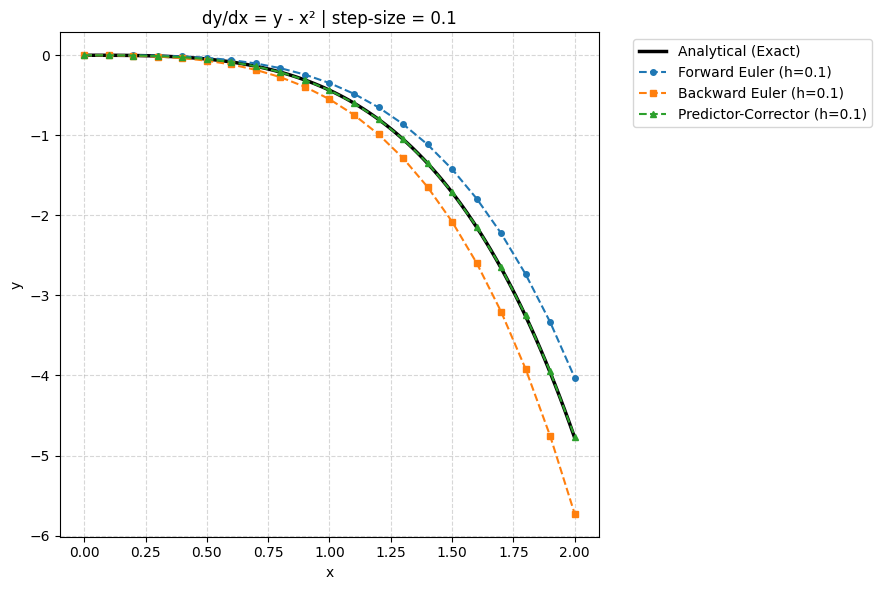

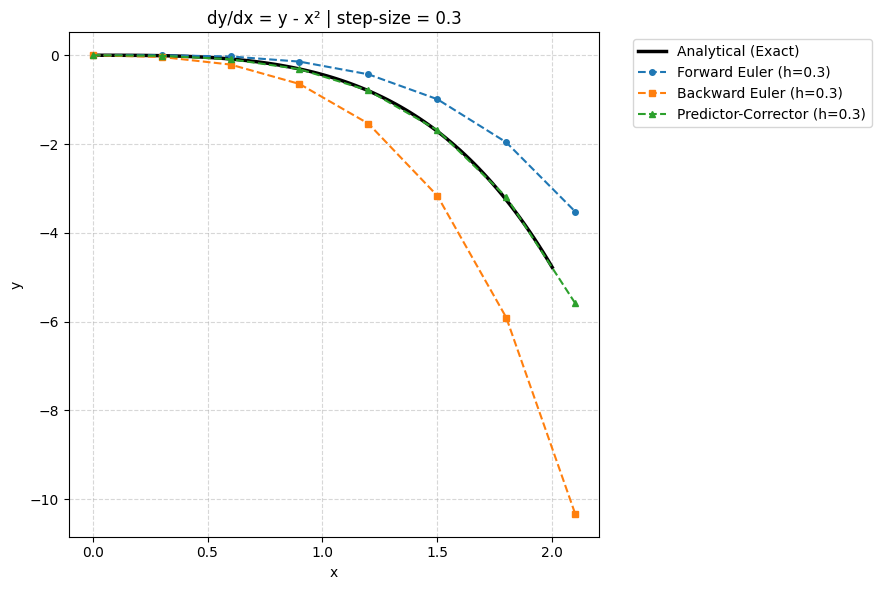

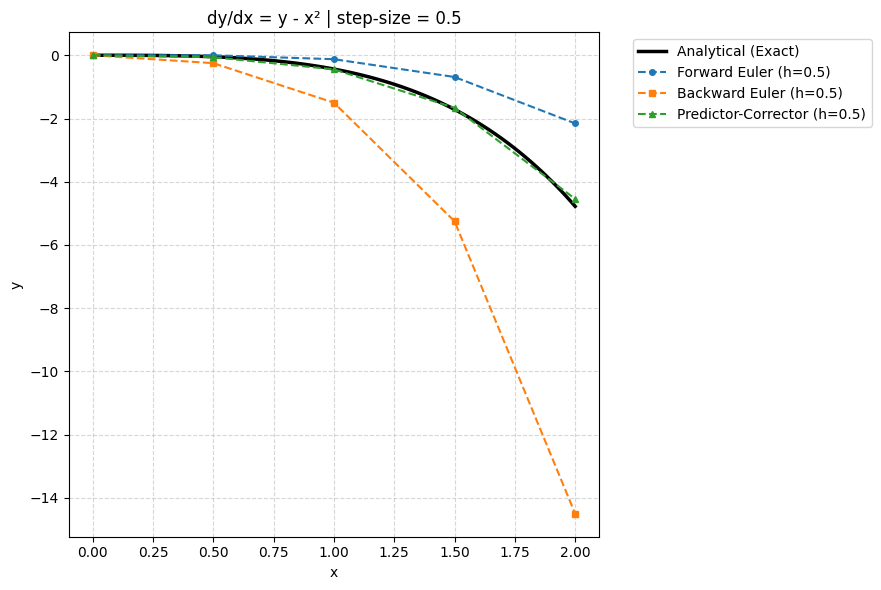

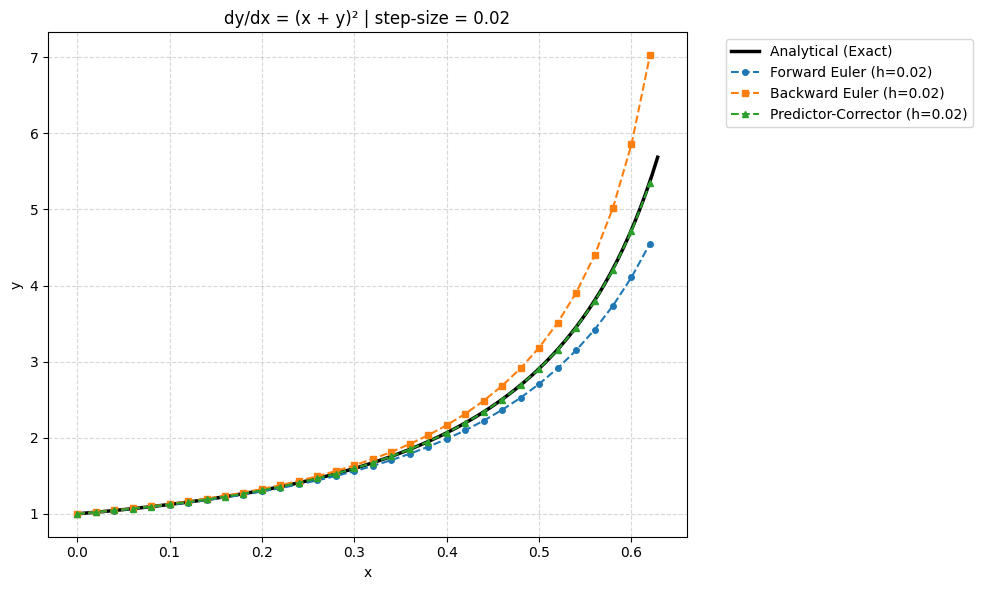

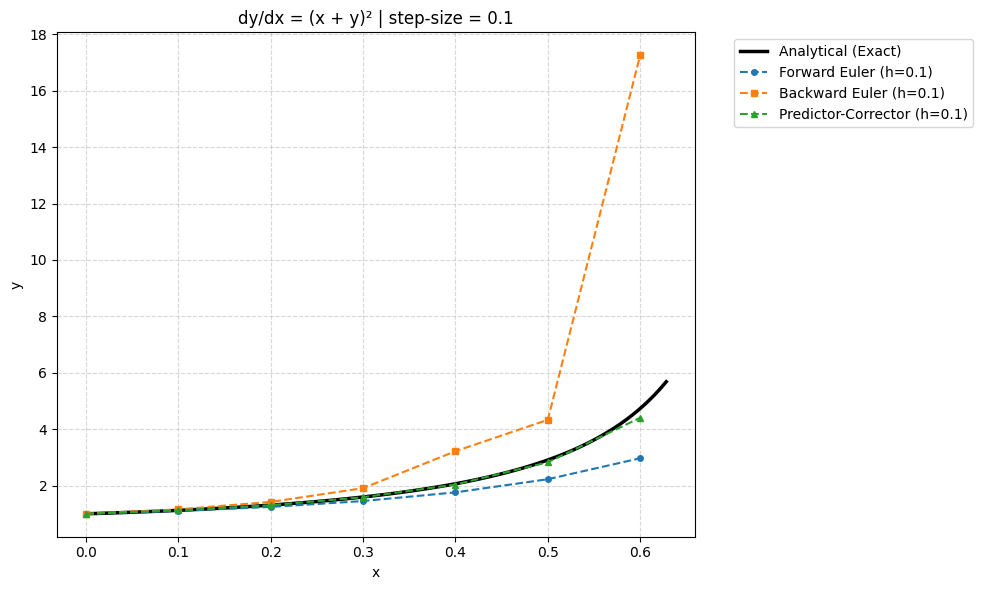

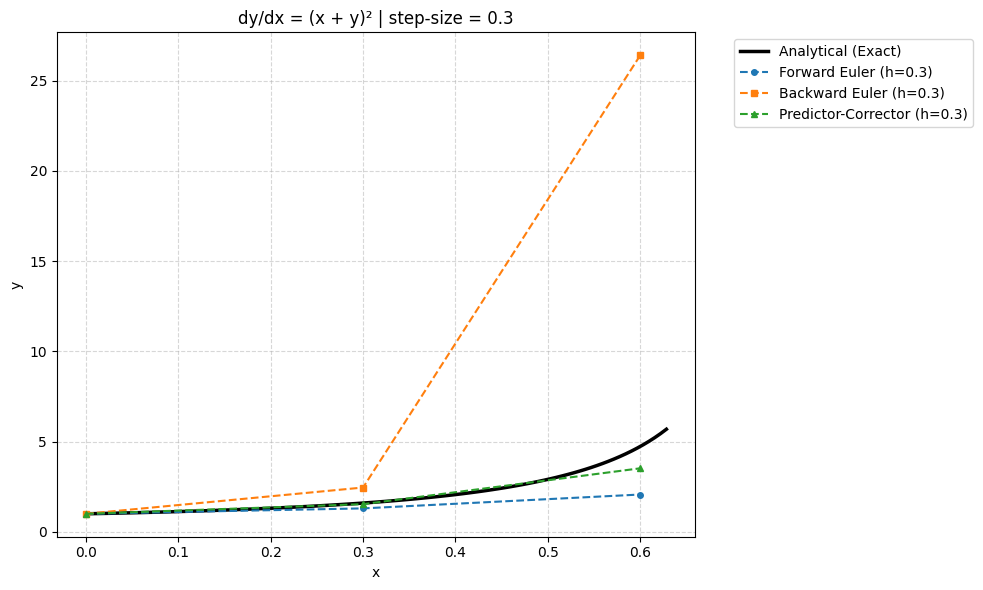

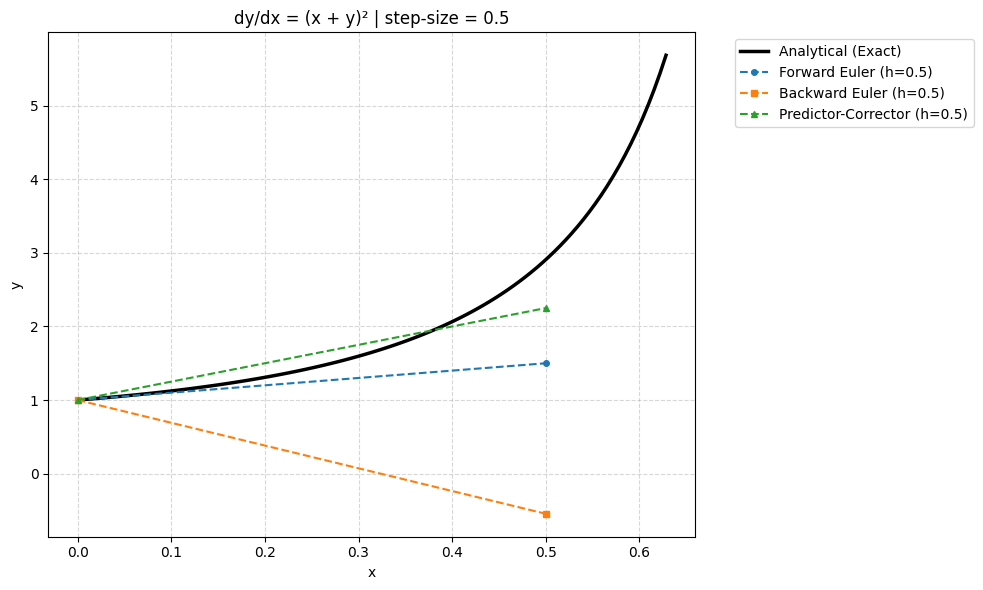

In [4]:
import matplotlib.pyplot as plt

def f1(x, y):
    return y - x**2

def df1_dy(x, y): 
    return 1.0

def y1(x):
    return x**2 + 2*x + 2 - 2*math.exp(x)

# Case 2: dy/dx = (x + y)^2
def f2(x, y):
    return (x + y)**2

def df2_dy(x, y): 
    return 2.0 * (x + y)

def y2(x):
    return math.tan(x + math.pi/4) - x

step_sizes = [0.02, 0.1, 0.3, 0.5]


x_fine1 = [i * 2.0 / 100 for i in range(101)]
y_fine1 = [y1(x) for x in x_fine1]

for h in step_sizes:
    xval, y_fe = forward_euler(f1, 0.0, 0.0, 2.0, h)
    xval, y_be = backward_euler(f1, df1_dy, 0.0, 0.0, 2.0, h)
    xval, y_pc = predictor_corrector(f1, 0.0, 0.0, 2.0, h)
    plt.figure(figsize=(9, 6))
    plt.plot(x_fine1, y_fine1, label="Analytical (Exact)", color="black", linewidth=2.5)
    plt.plot(xval, y_fe, "o--", label=f"Forward Euler (h={h})", markersize=4)
    plt.plot(xval, y_be, "s--", label=f"Backward Euler (h={h})", markersize=4)
    plt.plot(xval, y_pc, "^--", label=f"Predictor-Corrector (h={h})", markersize=4)
    plt.title(f"dy/dx = y - x² | step-size = {h}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()


end_x = math.pi / 5
x_fine2 = [i * end_x / 100 for i in range(101)]
y_fine2 = [y2(x) for x in x_fine2]


for h in step_sizes:
    end_x = math.pi / 5
    xval, y_fe = forward_euler(f2, 0.0, 1.0, end_x, h)
    xval, y_be = backward_euler(f2, df2_dy, 0.0, 1.0, end_x, h)
    xval, y_pc = predictor_corrector(f2, 0.0, 1.0, end_x, h)
    plt.figure(figsize=(10, 6))
    plt.plot(x_fine2, y_fine2, label="Analytical (Exact)", color="black", linewidth=2.5)
    plt.plot(xval, y_fe, "o--", label=f"Forward Euler (h={h})", markersize=4)
    plt.plot(xval, y_be, "s--", label=f"Backward Euler (h={h})", markersize=4)
    plt.plot(xval, y_pc, "^--", label=f"Predictor-Corrector (h={h})", markersize=4)
    plt.title(f"dy/dx = (x + y)² | step-size = {h}")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()

plt.show()